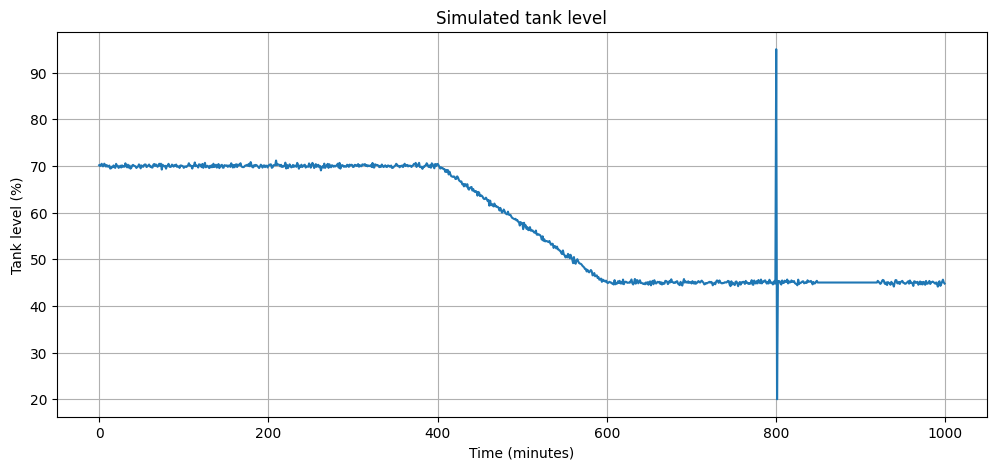

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

n = 1000
time = np.arange(n)

level = 70 + np.random.normal(0, 0.3, n)

level[400:600] = np.linspace(70, 45, 200) + np.random.normal(0, 0.3, 200)
level[600:] = level[600:] - 25 + 25
level[600:] = 45 + np.random.normal(0, 0.3, n - 600)

level[800] = 95
level[801] = 20

level[850:920] = level[849]

plt.figure(figsize=(12, 5))
plt.plot(time, level)
plt.xlabel("Time (minutes)")
plt.ylabel("Tank level (%)")
plt.title("Simulated tank level")
plt.grid(True)
plt.show()

In [2]:
import pandas as pd

df = pd.DataFrame({"time": time, "level": level})

df["rate"] = df["level"].diff()

df["trend"] = df["level"].rolling(window=20).mean().diff()

df["rolling_std"] = df["level"].rolling(window=10).std()

df["is_flat"] = df["rolling_std"] < 0.05

group_id = (df["is_flat"] != df["is_flat"].shift()).cumsum()
df["flat_duration"] = df.groupby(group_id).cumcount() + 1
df.loc[~df["is_flat"], "flat_duration"] = 0

print(df[df["rate"].abs() > 5])
print("أطول فترة ثبات:", df["flat_duration"].max(), "دقيقة")
print("متوسط الميل أثناء الهبوط الحقيقي:", df.loc[450:590, "trend"].mean())

     time      level       rate     trend  rolling_std  is_flat  flat_duration
800   800  95.000000  50.197068  2.489831    15.819428    False              0
801   801  20.000000 -75.000000 -1.242681    18.448146    False              0
802   802  45.355711  25.355711 -0.014574    18.451158    False              0
أطول فترة ثبات: 62 دقيقة
متوسط الميل أثناء الهبوط الحقيقي: -0.12657984051397791


state
normal          561
real_low        366
sensor_stuck     70
sensor_spike      3
Name: count, dtype: int64


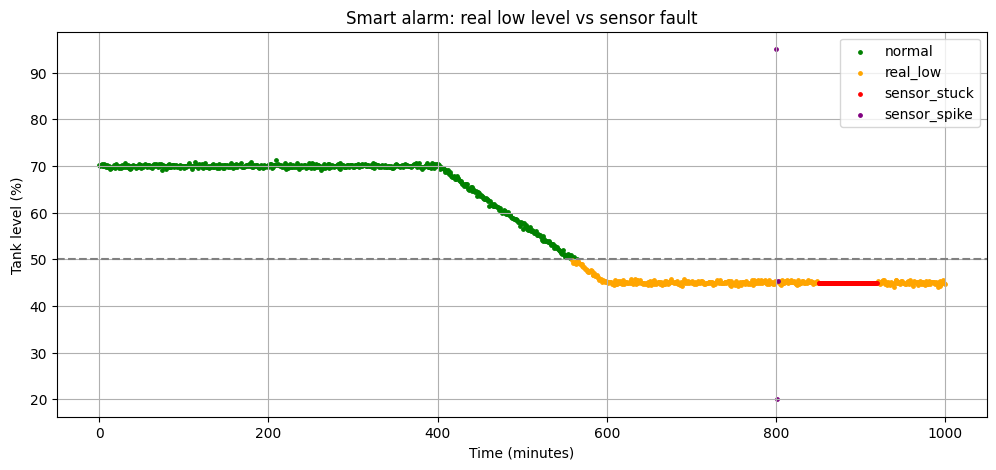

In [4]:
group_total = df.groupby(group_id)["flat_duration"].transform("max")
df["stuck"] = df["is_flat"] & (group_total >= 30)

df["spike"] = df["rate"].abs() > 5
s = df["stuck"].copy()
for k in range(1, 9):
    df["stuck"] = df["stuck"] | s.shift(-k, fill_value=False)
df["state"] = "normal"
df.loc[df["level"] < 50, "state"] = "real_low"
df.loc[df["stuck"], "state"] = "sensor_stuck"
df.loc[df["spike"], "state"] = "sensor_spike"

print(df["state"].value_counts())

colors = {
    "normal": "green",
    "real_low": "orange",
    "sensor_stuck": "red",
    "sensor_spike": "purple",
}

plt.figure(figsize=(12, 5))
for state, color in colors.items():
    part = df[df["state"] == state]
    plt.scatter(part["time"], part["level"], s=6, c=color, label=state)

plt.axhline(50, linestyle="--", color="gray")
plt.xlabel("Time (minutes)")
plt.ylabel("Tank level (%)")
plt.title("Smart alarm: real low level vs sensor fault")
plt.legend()
plt.grid(True)
plt.show()